# Chapitre 9 - Cours 2 : ordre, identifiants et horloges logiques

Attribuer un identifiant à un enregistrement semble sans rapport avec la cohérence. Et
pourtant : si les identifiants servent à **ordonner** les événements (afficher une
conversation, choisir le gagnant d'une réservation, construire un instantané), leur
ordre doit respecter la **causalité**, voire le **temps réel**. Ce notebook part de la
relation « s'est produit avant », compare les générateurs d'identifiants distribués,
implémente les horloges de Lamport et vectorielles, et montre pourquoi des horodatages,
même bien ordonnés, ne suffisent pas à imposer une contrainte d'unicité. Il couvre la section *Ordering Guarantees* du chapitre : *Ordering and Causality* (*The causal order is not a total order*, *Linearizability is stronger than causal consistency*, *Capturing causal dependencies*) et *Sequence Number Ordering* (*Noncausal sequence number generators*, *Lamport timestamps*, *Timestamp ordering is not sufficient*). La fin de la section, *Total Order Broadcast*, est traitée avec le consensus au cours 4.

**Plan.**

1. Causalité : un ordre partiel.
2. Un compteur sur un seul nœud : ordonné, linéarisable, mais fragile.
3. Les générateurs distribués perdent l'ordre.
4. Les horloges de Lamport : un ordre total compatible avec la causalité.
5. Les horloges vectorielles : reconnaître la concurrence.
6. Des horodatages ne suffisent pas à imposer une contrainte.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import consistency as cs
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, DIV, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Causalité : un ordre partiel (section *Ordering and Causality*)

L'**ordre** revient sans cesse dans ce livre : le leader impose l'ordre des écritures
dans le journal de réplication, la sérialisabilité fait comme si les transactions
s'exécutaient dans un certain ordre, les horodatages des horloges servent à décider
quelle écriture est la plus récente. Une raison profonde : l'ordre aide à préserver la
**causalité**. Une réponse vient après la question à laquelle elle répond ; une ligne ne
peut être modifiée qu'après avoir été créée ; un instantané cohérent contient les effets
de tout ce qui a précédé causalement ce qu'il contient.

**La relation « s'est produit avant »** (happens-before, chapitre 5). Un
événement $a$ précède causalement $b$ ($a \to b$) si : $a$ et $b$ ont lieu sur le même
nœud et $a$ vient d'abord ; ou $a$ est l'envoi d'un message et $b$ sa réception ; ou il
existe $c$ avec $a \to c$ et $c \to b$. Si ni $a \to b$ ni $b \to a$, les deux
événements sont **concurrents** ($a \parallel b$) : aucun n'a pu influencer l'autre.

C'est un **ordre partiel** : deux événements concurrents ne sont pas comparables. Un ordre
**total**, lui, compare n'importe quelle paire (deux entiers, par exemple). La
linéarisabilité impose un ordre total (une seule copie, des opérations atomiques une à
une) ; la causalité, seulement un ordre partiel. Rejouons un échange entre trois nœuds et
calculons la relation entre chaque paire d'événements.

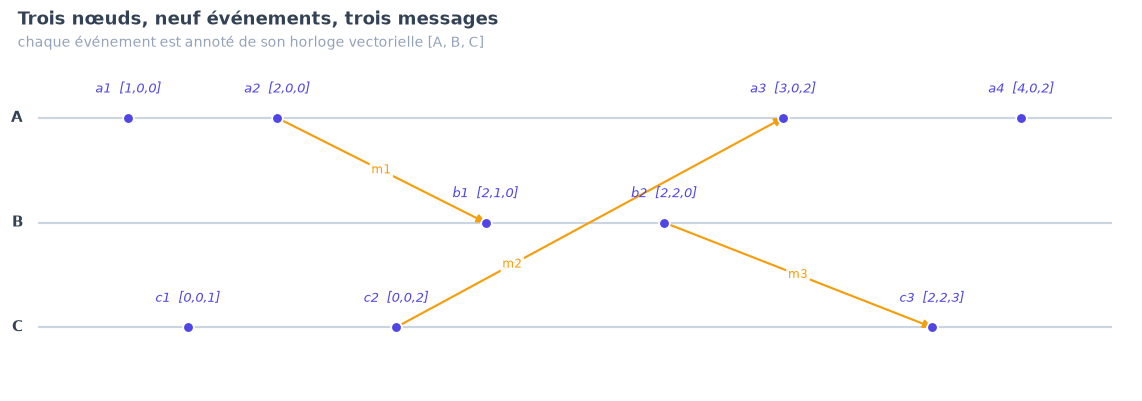

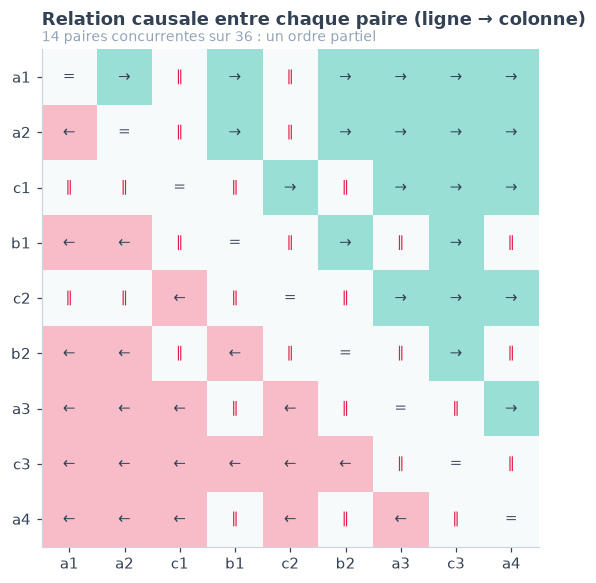

In [2]:
def rejoue(actions, nodes):
    """actions : ('local', nœud, nom) | ('send', nœud, nom, msg) | ('recv', nœud, nom, msg).
    Renvoie la liste des événements avec horloges de Lamport et vectorielles."""
    lam = {n: cs.LamportClock(n) for n in nodes}
    vec = {n: cs.VectorClock(n, nodes) for n in nodes}
    sent, out = {}, []
    for a in actions:
        kind, node, name = a[:3]
        if kind == "recv":
            lam[node].observe(sent[a[3]][0]); vec[node].observe(sent[a[3]][1])
        ev = dict(nom=name, nœud=node, type=kind, lamport=lam[node].tick(), vc=vec[node].tick())
        if kind == "send":
            sent[a[3]] = (ev["lamport"], ev["vc"])
        out.append(ev)
    return out

nodes = ["A", "B", "C"]
actions = [("local", "A", "a1"), ("send", "A", "a2", "m1"), ("local", "C", "c1"), ("recv", "B", "b1", "m1"),
           ("send", "C", "c2", "m2"), ("send", "B", "b2", "m3"), ("recv", "A", "a3", "m2"),
           ("recv", "C", "c3", "m3"), ("local", "A", "a4")]
evs = rejoue(actions, nodes)
pos = {"a1": 0.6, "a2": 1.6, "c1": 1.0, "b1": 3.0, "c2": 2.4, "b2": 4.2, "a3": 5.0, "c3": 6.0, "a4": 6.6}
msgs = {"m1": ("a2", "b1"), "m2": ("c2", "a3"), "m3": ("b2", "c3")}
st = SpaceTime(nodes, t_max=7.2, width=10.5, title="Trois nœuds, neuf événements, trois messages",
               subtitle="chaque événement est annoté de son horloge vectorielle [A, B, C]", show_axis=False)
for m, (s_, r_) in msgs.items():
    st.msg(evs[[e["nom"] for e in evs].index(s_)]["nœud"], pos[s_], evs[[e["nom"] for e in evs].index(r_)]["nœud"], pos[r_],
           m, color=AMBER, label_pos=0.3 if m == "m2" else 0.5)
for e in evs:
    st.event(e["nœud"], pos[e["nom"]], "", color=INDIGO)
    st.note(pos[e["nom"]], e["nœud"], f"{e['nom']}  [{','.join(str(v) for v in e['vc'].values())}]", dy=0.28,
            color=INDIGO, fontsize=8.5)
st.show()

names = [e["nom"] for e in evs]
code = {"<": 1, ">": -1, "=": 0, "||": 0}
M = np.array([[code[cs.vc_compare(a["vc"], b["vc"])] for b in evs] for a in evs])
conc = np.array([[cs.vc_compare(a["vc"], b["vc"]) == "||" for b in evs] for a in evs])
fig, ax = plt.subplots(figsize=(6.4, 5.4))
ax.imshow(M, cmap=DIV, vmin=-1.6, vmax=1.6)
for i in range(len(evs)):
    for j in range(len(evs)):
        sym = {1: "→", -1: "←", 0: "∥" if conc[i, j] else "="}[M[i, j]]
        ax.text(j, i, sym, ha="center", va="center", fontsize=10, color=SLATE if sym != "∥" else ROSE)
ax.set_xticks(range(len(evs)), names); ax.set_yticks(range(len(evs)), names)
ax.grid(False)
ax.set_title("Relation causale entre chaque paire (ligne → colonne)")
subtitle(ax, f"{conc.sum() // 2} paires concurrentes sur {len(evs) * (len(evs) - 1) // 2} : un ordre partiel")
plt.tight_layout(); plt.show()

Lecture de la matrice : `a1 → b1` (a1 précède l'envoi de m1, reçu en b1) ; `c1 ∥ a2`
(aucun chemin de messages entre eux) ; `a1 → c3` par la chaîne a1, a2, m1, b1, b2, m3,
c3. Un événement est comparé à un autre **seulement** s'il existe un chemin dans le
diagramme espace-temps. On dit qu'un système est **cohérent avec la causalité** s'il
respecte cet ordre partiel : par exemple, l'isolation par instantané (chapitre
7) exige qu'un instantané qui contient un événement contienne aussi
tout ce qui l'a causé.

**La linéarisabilité est plus forte que la cohérence causale** (*Linearizability is
stronger than causal consistency*). Un système linéarisable respecte forcément la
causalité (il impose un ordre total compatible avec le temps réel, donc avec tous les
chemins de messages). Mais la réciproque est fausse, et c'est une bonne nouvelle : la
**cohérence causale** est le modèle le plus fort connu qui ne ralentisse pas avec les
délais du réseau et qui reste disponible pendant une partition. Beaucoup de systèmes qui
semblent avoir besoin de linéarisabilité n'ont en fait besoin que de causalité.

**Capturer les dépendances causales** (*Capturing causal dependencies*). Pour respecter
la causalité, un nœud doit savoir ce qui précède quoi : quand une réplique traite une
opération, tout ce qui l'a précédée causalement doit déjà être traité, sinon elle doit
attendre. Les **vecteurs de versions** du chapitre 5 généralisés à toute la
base font ce suivi ; SSI (chapitre 7) suit de la même façon les versions lues
par chaque transaction. Ce suivi coûte cher : d'où les **numéros de séquence**, plus
compacts, de la suite.

> **À retenir.** La causalité ($a \to b$ : un chemin de messages ou d'événements locaux
> mène de $a$ à $b$) est un ordre **partiel** ; les événements sans chemin entre eux sont
> concurrents. Un ordre total (linéarisabilité, numéros de séquence) compare tout.

## 2. Un compteur sur un seul nœud : ordonné, linéarisable, mais fragile (section *Sequence Number Ordering*)

Une base sur un seul nœud attribue souvent des clés primaires par **auto-incrément** :
64 bits suffisent (32 si l'on est sûr de ne jamais dépasser 4 milliards
d'enregistrements, pari risqué). En prime, l'ordre des identifiants est l'ordre de
création : dans une messagerie, trier par identifiant affiche les messages dans un ordre
qui a du sens (une réponse a un identifiant plus grand que la question).

Ce générateur est **linéarisable** : chaque demande est un `fetch-and-add` atomique
(incrémenter un compteur et renvoyer l'ancienne valeur). Si la demande A se termine avant
que la demande B ne commence, B reçoit un identifiant plus grand, même si A et B n'ont
jamais communiqué. Deux demandes concurrentes reçoivent des identifiants distincts, dans
un ordre quelconque.

En mémoire, c'est une instruction atomique du processeur. Le rendre persistant demande
un peu plus d'effort (un redémarrage ne doit pas remettre le compteur à zéro, sinon les
identifiants se répètent). Mais ses vrais défauts sont ailleurs : c'est un **point de
défaillance unique**, un **goulot d'étranglement** potentiel, et il est **loin** de
certains clients.

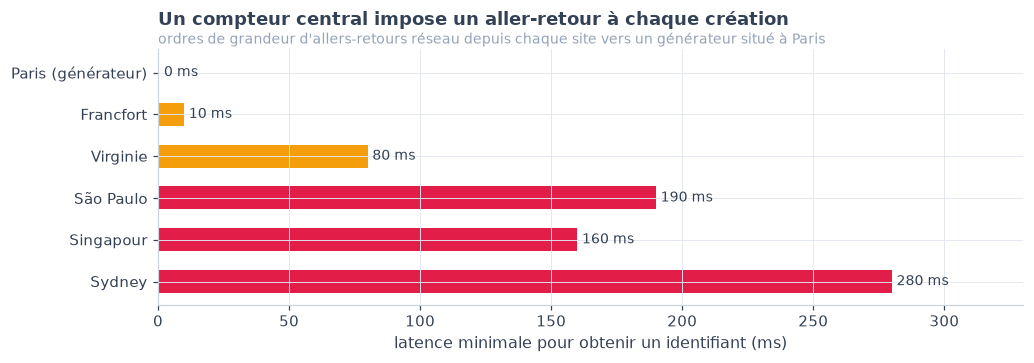

In [3]:
regions = pd.DataFrame({"site": ["Paris (générateur)", "Francfort", "Virginie", "São Paulo", "Singapour", "Sydney"],
                        "aller_retour_ms": [0.5, 10, 80, 190, 160, 280]})
fig, ax = plt.subplots(figsize=(9.5, 3.4))
cols = [GREEN] + [AMBER if v < 100 else ROSE for v in regions.aller_retour_ms[1:]]
ax.barh(regions.site[::-1], regions.aller_retour_ms[::-1], color=cols[::-1], height=0.55)
annotate_bars(ax, "{:.0f} ms")
ax.set_xlabel("latence minimale pour obtenir un identifiant (ms)")
ax.set_xlim(0, 330)
ax.set_title("Un compteur central impose un aller-retour à chaque création")
subtitle(ax, "ordres de grandeur d'allers-retours réseau depuis chaque site vers un générateur situé à Paris")
plt.tight_layout(); plt.show()

Un client de Sydney paie plus d'un quart de seconde **avant même** d'écrire son
enregistrement. D'où l'envie de distribuer la génération d'identifiants.

> **À retenir.** Un compteur sur un nœud donne des identifiants compacts, uniques et
> ordonnés comme le temps réel (il est linéarisable), mais il n'est ni tolérant aux
> pannes, ni proche de tous les clients, ni extensible.

## 3. Les générateurs distribués perdent l'ordre (section *Noncausal sequence number generators*)

Trois façons classiques de générer des identifiants sur plusieurs nœuds sans coordination
à chaque demande :

- **par partition** : le nœud $k$ sur $n$ distribue $k, k + n, k + 2n$... (pairs
  et impairs pour deux nœuds) ; plus généralement, quelques bits de l'identifiant
  contiennent le numéro du nœud ;
- **par blocs préalloués** : chaque nœud réserve auprès d'un générateur central un bloc
  (1 à 1 000, puis 1 001 à 2 000...) et le distribue localement ;
- **par horloge murale** : l'heure du nœud (synchronisée par NTP) dans les bits de poids
  fort, complétée par le numéro du nœud et une séquence pour garantir l'unicité.

Tous trois donnent des identifiants **uniques**. Mesurons leur **ordre** : 3 nœuds
traitent 20 000 demandes réparties au hasard ; le nœud 2 reçoit deux fois plus de
demandes que les autres ; les horloges sont décalées de -3, 0 et +5 ms. Pour un écart
$g$, on estime la probabilité qu'une demande commencée $g$ **après** une autre reçoive un
identifiant **plus petit** (`cs.assign_ids`, `cs.inversion_curve`).

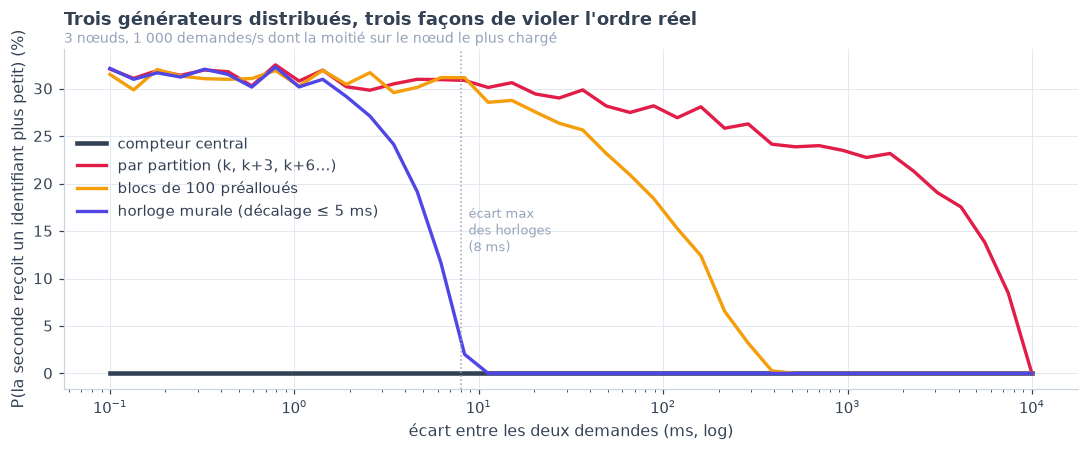

,écart 1.91 ms,écart 36.7 ms,écart 702 ms,écart 1e+04 ms
compteur central,0.000,0.000,0.00,0.0
"par partition (k, k+3, k+6...)",0.302,0.299,0.24,0.0
blocs de 100 préalloués,0.305,0.257,0.00,0.0
horloge murale (décalage ≤ 5 ms),0.292,0.000,0.00,0.0


In [4]:
N = 20_000
times = np.sort(rng.uniform(0, 20.0, N))                      # 20 s, 1 000 demandes/s
nodes_ = rng.choice(3, N, p=[0.25, 0.25, 0.5])
offs = [-0.003, 0.0, 0.005]
gaps = np.geomspace(1e-4, 10, 40)
schemes = {"central": ("compteur central", SLATE), "sharded": ("par partition (k, k+3, k+6...)", ROSE),
           "blocks": ("blocs de 100 préalloués", AMBER), "wallclock": ("horloge murale (décalage ≤ 5 ms)", INDIGO)}
fig, ax = plt.subplots(figsize=(10, 4.2))
curves = {}
for sch, (lab, c) in schemes.items():
    ids = cs.assign_ids(sch, times, nodes_, 3, block=100, offsets=offs)
    curves[sch] = cs.inversion_curve(times, ids, gaps, n_pairs=6000, seed=1)
    ax.plot(gaps * 1000, curves[sch] * 100, color=c, label=lab, lw=2.2 if sch != "central" else 3)
ax.set_xscale("log")
ax.axvline(8, color=GRAY, ls=":", lw=1)
ax.text(8.8, 15, "écart max\ndes horloges\n(8 ms)", fontsize=8.5, color=GRAY, va="center")
ax.set_xlabel("écart entre les deux demandes (ms, log)")
ax.set_ylabel("P(la seconde reçoit un identifiant plus petit) (%)")
ax.set_title("Trois générateurs distribués, trois façons de violer l'ordre réel")
subtitle(ax, "3 nœuds, 1 000 demandes/s dont la moitié sur le nœud le plus chargé")
ax.legend(loc="center left", bbox_to_anchor=(0.0, 0.62))
plt.tight_layout(); plt.show()
pd.DataFrame({schemes[k][0]: v[[10, 20, 30, 39]] for k, v in curves.items()},
             index=[f"écart {g * 1000:.3g} ms" for g in gaps[[10, 20, 30, 39]]]).T

- **Par partition** : les compteurs avancent à des vitesses différentes (le nœud chargé
  distribue deux fois plus vite), si bien que l'écart entre compteurs **grandit avec le
  temps** : au bout de $t$ secondes, une demande servie par un nœud peu chargé peut
  recevoir un identifiant plus petit qu'une demande antérieure de près de $t$ secondes.
  La courbe ne retombe à droite que parce que la simulation ne dure que 20 s ; sur un an,
  l'ordre ne voudrait plus rien dire.
- **Par blocs** : tant que les deux demandes tombent dans des blocs différents encore en
  cours, l'ordre est arbitraire ; il ne se rétablit qu'au-delà de la durée de vie d'un bloc.
- **Par horloge murale** : l'ordre n'est faux que pour des demandes plus proches que le
  décalage des horloges (quelques ms) ; au-delà, il est correct. C'est le meilleur des
  trois... **si** les horloges restent synchronisées : un saut d'horloge (NTP qui recule)
  désordonne même les identifiants d'un seul nœud (chapitre 8).

Aucun n'est **cohérent avec la causalité** : si un nœud lent attribue l'identifiant d'une
réponse, celle-ci peut paraître antérieure à la question.

> **À retenir.** Partition, blocs, horloge murale : trois générateurs uniques et sans
> coordination, mais dont l'ordre ne respecte ni le temps réel ni la causalité. Le moins
> mauvais (l'horloge) ne se trompe qu'à l'échelle du décalage des horloges.